In [3]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error       # 평균절대값오차 오차범위
from sklearn.model_selection import train_test_split  # 정규화 클래스
from sklearn.preprocessing import StandardScaler

결혼식장에서 참석인원이 식사를 하고 가는 사람을 파악해서 음식을 준비하려고 합니다.
1. 참석인원(total), 식사인원(reception)을 학습하여 참석 300명일때 식사인원을 예측하시오.
2. 산점도 그래프와 직선 그래프를 출력하시오

In [42]:
df = pd.read_csv('data/QuizData.csv')  # ,쉼표
df.head(2)

,total,reception
0,118,62
1,253,148


In [45]:
lr = LinearRegression()
lr.fit(data,label) # 2차원배열

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[0.51]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[22.56]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[368.22]


In [38]:
data = df.iloc[:,:-1].values[:2]

In [43]:
data = df.iloc[:,0].values
data.reshape(-1,1)

array([[118],
       [253],
       [320],
       [ 94],
       [155],
       [188],
       [201],
       [338],
       [186],
       [183],
       [223],
       [392],
       [ 86],
       [112],
       [129],
       [223],
       [288],
       [262],
       [143],
       [179]])

In [44]:
data = df.iloc[:,:-1].values
label = df.iloc[:,1:].values

In [27]:
data[:2]
label[:2]

array([[ 62],
       [148]])

In [28]:
train_data, test_data, train_label, test_label = train_test_split(data,label)

In [29]:
# 데이터 학습
lr = LinearRegression()
lr.fit(train_data,train_label)
# 데이터 예측
predict = lr.predict(test_data)
print('예측인원 : ',predict)
# 정확도
score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print('train 정확도 : ',score)
print('test 정확도 : ',score2)

예측인원 :  [[156.1926306 ]
 [118.64678481]
 [151.62624395]
 [169.38441425]
 [ 66.89440278]]
train 정확도 :  0.874456175645322
test 정확도 :  0.85460243479283


예측 식사인원 : [[175.47292979]]


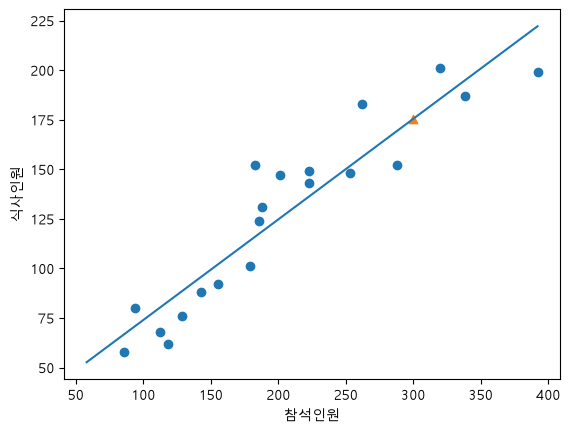

In [30]:
# 점수입력
in_data = input('참석인원을 입력하세요.>> (예: 300)')
in_data = float(in_data)
result = lr.predict([[in_data]])
print("예측 식사인원 :",result)

# 산점도 그래프
plt.scatter(data,label)
plt.scatter(in_data,result,marker='^')
plt.plot([58,392],[58*lr.coef_[0]+lr.intercept_,392*lr.coef_[0]+lr.intercept_])
plt.xlabel('참석인원')
plt.ylabel('식사인원')
plt.show()